# Predict which customers will churn, so the retention team can contact the riskiest ones first.

### Load, split, basic checks

In [1]:

import pandas as pd, numpy as np, os
from sklearn.model_selection import train_test_split
os.makedirs('outputs/figures',exist_ok=True)
df=pd.read_csv('data/telco_churn.csv')
print(df.shape, df.customerID.nunique(), df.duplicated().sum())
df['TotalCharges']=pd.to_numeric(df.TotalCharges,errors='coerce')
print(df.isna().sum()[lambda s:s>0])
print(df.Churn.value_counts(normalize=True))
y=(df.Churn=='Yes').astype(int); X=df.drop(columns=['Churn','customerID'])
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
print(Xtr.shape,Xte.shape)
print(df[df.TotalCharges.isna()][['tenure','MonthlyCharges']].head(3))


(7043, 21) 7043 0
TotalCharges    11
dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64
(5634, 19) (1409, 19)
     tenure  MonthlyCharges
488       0           52.55
753       0           20.25
936       0           80.85


### EDA on training data

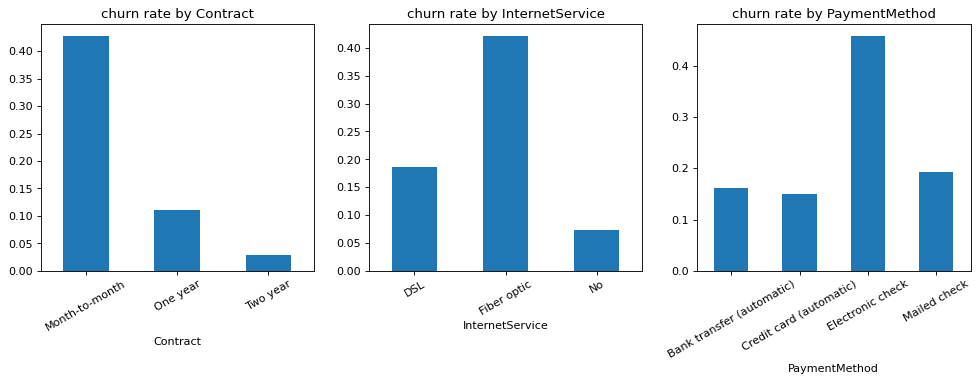

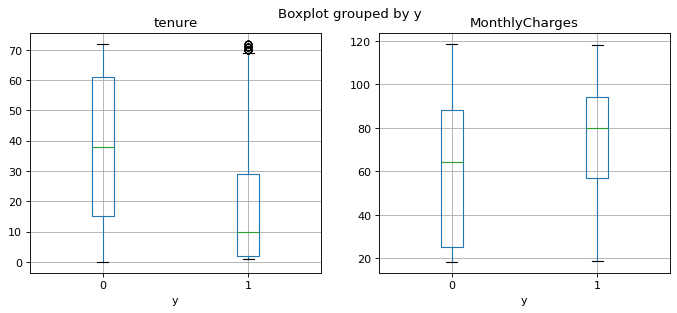

tenure           -0.345593
MonthlyCharges    0.198040
TotalCharges     -0.194814
y                 1.000000
Name: y, dtype: float64


In [2]:

import matplotlib.pyplot as plt
tr=Xtr.copy(); tr['y']=ytr
fig,ax=plt.subplots(1,3,figsize=(15,4))
for c,a in zip(['Contract','InternetService','PaymentMethod'],ax):
    tr.groupby(c).y.mean().plot.bar(ax=a,title='churn rate by '+c); a.tick_params(axis='x',rotation=30)
plt.savefig('outputs/figures/churn_by_cat.png',bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(1,2,figsize=(10,4))
tr.boxplot('tenure',by='y',ax=ax[0]); tr.boxplot('MonthlyCharges',by='y',ax=ax[1])
plt.savefig('outputs/figures/num_by_churn.png',bbox_inches='tight'); plt.show()
print(tr[['tenure','MonthlyCharges','TotalCharges','y']].corr()['y'])


**Checkpoint.** Telco churn: 7043 customers, unique IDs, no duplicates, 26.5% churn. Stratified 80/20 split done (random, since no time column and one row per customer). TotalCharges has 11 blanks (all tenure=0 new customers) -> will impute 0. Strong signals: month-to-month contract (43% churn vs 3% for two-year), fiber optic (42%), electronic check (46%), low tenure. No leakage found; customerID dropped.

### Baselines with CV

In [3]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
cat=[c for c in Xtr if Xtr[c].dtype==object]; num=[c for c in Xtr if c not in cat]
def prep(scale=True):
    return ColumnTransformer([('n',Pipeline([('i',SimpleImputer(strategy='constant',fill_value=0)),('s',StandardScaler() if scale else 'passthrough')]),num),
                              ('c',OneHotEncoder(handle_unknown='ignore'),cat)])
cv=StratifiedKFold(5,shuffle=True,random_state=42)
def ev(m):
    r=cross_validate(m,Xtr,ytr,cv=cv,scoring=['roc_auc','average_precision'])
    return {'roc_auc':r['test_roc_auc'].mean(),'pr_auc':r['test_average_precision'].mean(),'cv_std':r['test_roc_auc'].std()}
res={}
res['dummy']=ev(DummyClassifier(strategy='prior'))
res['logreg']=ev(Pipeline([('p',prep()),('m',LogisticRegression(max_iter=1000))]))
print(res)


{'dummy': {'roc_auc': np.float64(0.5), 'pr_auc': np.float64(0.2653532460941748), 'cv_std': np.float64(0.0)}, 'logreg': {'roc_auc': np.float64(0.8462007441910661), 'pr_auc': np.float64(0.6616561497949907), 'cv_std': np.float64(0.012576130140361557)}}


**Checkpoint.** 5-fold CV on train: dummy ROC AUC 0.50 / PR AUC 0.265; logistic regression ROC AUC 0.846 / PR AUC 0.662 (std 0.013).

### LightGBM, RF, and engineered features

In [4]:

import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import FunctionTransformer
svc=['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
def fe(d):
    d=d.copy()
    d['TotalCharges']=pd.to_numeric(d.TotalCharges,errors='coerce').fillna(0)
    d['n_services']=(d[svc]=='Yes').sum(axis=1)
    d['avg_charge']=d.TotalCharges/d.tenure.clip(lower=1)
    d['charge_diff']=d.MonthlyCharges-d.avg_charge
    return d
FE=FunctionTransformer(fe)
def pl(m,scale=False,feat=True):
    global num
    return m
cat=[c for c in Xtr if Xtr[c].dtype==object]
num2=num+['n_services','avg_charge','charge_diff']
def mk(model,scale=False):
    ct=ColumnTransformer([('n',StandardScaler() if scale else 'passthrough',num2),('c',OneHotEncoder(handle_unknown='ignore'),cat)])
    return Pipeline([('fe',FE),('p',ct),('m',model)])
models={'logreg_fe':mk(LogisticRegression(max_iter=2000),True),
 'lgbm':mk(lgb.LGBMClassifier(n_estimators=300,learning_rate=0.03,num_leaves=15,min_child_samples=30,subsample=0.8,subsample_freq=1,colsample_bytree=0.7,random_state=42,verbose=-1)),
 'rf':mk(RandomForestClassifier(500,min_samples_leaf=5,n_jobs=-1,random_state=42))}
for k,m in models.items():
    res[k]=ev(m); print(k,res[k])


logreg_fe {'roc_auc': np.float64(0.8456845610078991), 'pr_auc': np.float64(0.6595466127591356), 'cv_std': np.float64(0.012522133054941624)}


lgbm {'roc_auc': np.float64(0.8436961560274352), 'pr_auc': np.float64(0.6555925614269862), 'cv_std': np.float64(0.009155285242696936)}


rf {'roc_auc': np.float64(0.8450616552406794), 'pr_auc': np.float64(0.6579254514188522), 'cv_std': np.float64(0.008328644658400804)}


### Optuna tuning of LightGBM

In [5]:

import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
from sklearn.model_selection import cross_val_score
def obj(t):
    p=dict(n_estimators=t.suggest_int('n',100,600),learning_rate=t.suggest_float('lr',0.01,0.1,log=True),
      num_leaves=t.suggest_int('nl',3,31),min_child_samples=t.suggest_int('mcs',10,100),
      reg_lambda=t.suggest_float('rl',1e-2,30,log=True),colsample_bytree=t.suggest_float('cs',0.3,1),
      subsample=0.8,subsample_freq=1,random_state=42,verbose=-1)
    return cross_val_score(mk(lgb.LGBMClassifier(**p)),Xtr,ytr,cv=cv,scoring='roc_auc').mean()
st=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=42)); st.optimize(obj,n_trials=30)
print(st.best_value, st.best_params)
bp=st.best_params
best=dict(n_estimators=bp['n'],learning_rate=bp['lr'],num_leaves=bp['nl'],min_child_samples=bp['mcs'],reg_lambda=bp['rl'],colsample_bytree=bp['cs'],subsample=0.8,subsample_freq=1,random_state=42,verbose=-1)
res['lgbm_tuned']=ev(mk(lgb.LGBMClassifier(**best))); print(res['lgbm_tuned'])


0.849920769082485 {'n': 539, 'lr': 0.014313986309978462, 'nl': 5, 'mcs': 89, 'rl': 17.061338761299186, 'cs': 0.9671932207392042}


{'roc_auc': np.float64(0.849920769082485), 'pr_auc': np.float64(0.669304473184554), 'cv_std': np.float64(0.011836201367644184)}


### Final test evaluation, lift, importance, save

final lgbm AUC 0.8483 PR 0.6635
logreg AUC 0.8421 PR 0.6343
top 10%: precision 0.76, recall 0.29, lift 2.88
top 20%: precision 0.67, recall 0.51, lift 2.53
top 30%: precision 0.61, recall 0.68, lift 2.29
thr .5 prec 0.66 rec 0.52


Contract            0.0854
tenure              0.0555
InternetService     0.0105
OnlineSecurity      0.0064
PaymentMethod       0.0034
TechSupport         0.0030
PaperlessBilling    0.0025
MultipleLines       0.0023
dtype: float64


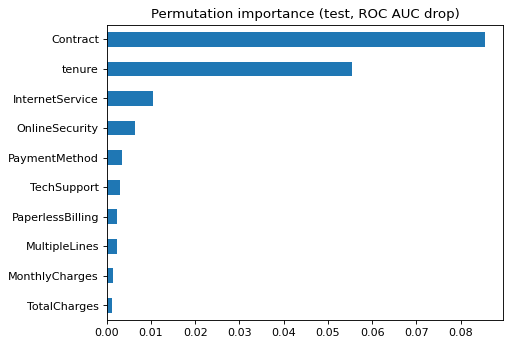

['outputs/model.joblib']

In [6]:

import joblib
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score
from sklearn.inspection import permutation_importance
final=mk(lgb.LGBMClassifier(**best)).fit(Xtr,ytr)
base=Pipeline([('p',prep()),('m',LogisticRegression(max_iter=1000))]).fit(Xtr,ytr)
for n,m in [('final lgbm',final),('logreg',base)]:
    p=m.predict_proba(Xte)[:,1]; print(n,'AUC %.4f PR %.4f'%(roc_auc_score(yte,p),average_precision_score(yte,p)))
p=final.predict_proba(Xte)[:,1]
o=np.argsort(-p)
for k in [0.1,0.2,0.3]:
    n=int(k*len(p)); top=yte.values[o[:n]]
    print(f'top {k:.0%}: precision {top.mean():.2f}, recall {top.sum()/yte.sum():.2f}, lift {top.mean()/yte.mean():.2f}')
pred=(p>=0.5).astype(int); print('thr .5 prec %.2f rec %.2f'%(precision_score(yte,pred),recall_score(yte,pred)))
pi=permutation_importance(final,Xte,yte,scoring='roc_auc',n_repeats=10,random_state=42)
imp=pd.Series(pi.importances_mean,index=Xte.columns).sort_values(ascending=False); print(imp.head(8).round(4))
imp.head(10)[::-1].plot.barh(title='Permutation importance (test, ROC AUC drop)'); plt.savefig('outputs/figures/importance.png',bbox_inches='tight'); plt.show()
joblib.dump(final,'outputs/model.joblib')


# Telco churn prediction

**Task:** rank customers by churn risk so the retention team can contact the riskiest first. Target `Churn` (Yes = 26.5%).
**Data:** 7,043 customers, one row each, 19 usable features. `customerID` was dropped. There were no duplicates. `TotalCharges` had 11 blanks, all for customers with tenure 0, and I filled them with 0.
**Split:** stratified random 80/20 split (5,634 train, 1,409 test), done before any analysis. I used a random split because the data has no time column and no repeated customers. The test set was used once, at the end.
**Metrics:** ROC AUC, which measures ranking quality, and PR AUC, which suits the 27% positive rate. I also report top-k% lift, because the use case is contacting the riskiest customers first.

## Leaderboard (5-fold CV on train)
| model | ROC AUC | PR AUC |
|---|---|---|
| dummy (prior) | 0.500 | 0.265 |
| logistic regression | 0.846 | 0.662 |
| logistic regression + engineered features | 0.846 | 0.660 |
| LightGBM (default-ish) | 0.844 | 0.656 |
| random forest | 0.845 | 0.658 |
| **LightGBM, Optuna-tuned (30 trials)** | **0.850** | **0.669** |

The engineered features were service count, average charge per month of tenure, and the gap between monthly and average charge. They did not help.

## Chosen model and test result
I chose the tuned LightGBM because it had the best CV score. The margin over logistic regression is small, about 0.004 AUC against a fold standard deviation of about 0.012, so the models are close to equivalent. The tuned model is somewhat optimistic on CV because the same folds were used for tuning.

| | test ROC AUC | test PR AUC |
|---|---|---|
| dummy | 0.50 | 0.27 |
| logistic regression | 0.842 | 0.634 |
| **tuned LightGBM** | **0.848** | **0.664** |

**Lift on the test set (tuned LightGBM):**
| contacted | precision | share of churners caught | lift |
|---|---|---|---|
| top 10% | 0.76 | 29% | 2.9x |
| top 20% | 0.67 | 51% | 2.5x |
| top 30% | 0.61 | 68% | 2.3x |

At a 0.5 probability threshold, precision is 0.66 and recall is 0.52.

## Key drivers
Permutation importance (`outputs/figures/importance.png`) shows that contract type and tenure dominate. Internet service type, online security, payment method and tech support follow at much lower importance. Churn is highest for month-to-month contracts (43%), fiber optic customers (42%), electronic-check payers (46%) and short-tenure customers (`outputs/figures/churn_by_cat.png`, `outputs/figures/num_by_churn.png`). I found no leakage. No single feature came close to a perfect score.

## Limitations
- The data is one snapshot with a random split. I could not check how the model holds up over time.
- The model ranks risk. It does not show which customers a retention offer would actually change. Uplift modelling or a trial would be needed for that.
- Probabilities are not explicitly calibrated.
- The test set has 1,409 rows, so the metrics carry noticeable uncertainty, roughly ±0.02 AUC.
- Contract and tenure carry most of the signal, so a simple rule-based segmentation would capture much of the value.

## Next steps
- Choose the contact budget (the top-k%) from the cost of an offer against the value of a retained customer.
- Calibrate the probabilities.
- Validate on later cohorts.
- Run a retention A/B test.

**Saved model:** `outputs/model.joblib`. It is a full sklearn Pipeline that takes the raw feature columns, with the engineered features, encoding and LightGBM inside.
